In [1]:
import numpy as np
import netCDF4 as nc4
import pickle as pkl
import matplotlib.pyplot as plt

In [2]:

M2_file = '/glade/u/home/wsmith/ASM_Plotter/Analysis_Files/MERRA2_400.tavg3_3d_mst_Np.20220818.nc4'
conv_dom = [110,122,36,42]
plot_lev = 250.

ts = [2,3,4,5]  # Time indices we want to include (code should make this inclusive)


In [3]:

M2nc = nc4.Dataset(M2_file)
M2lon = M2nc.variables['lon'][:]
M2lat = M2nc.variables['lat'][:]
M2prs = M2nc.variables['lev'][:]
#M2min = M2nc.variables['time'][:]  # This is in minutes since 0130UTC for some reason

M2levind = list(M2prs).index(plot_lev)

lonind0 = np.where(M2lon >= conv_dom[0])[0][0]
lonind1 = np.where(M2lon <= conv_dom[1])[0][-1]
latind0 = np.where(M2lat >= conv_dom[2])[0][0]
latind1 = np.where(M2lat <= conv_dom[3])[0][-1]

i = np.where((M2lon >= conv_dom[0]) & (M2lon <= conv_dom[1]))[0]
j = np.where((M2lat >= conv_dom[2]) & (M2lat <= conv_dom[3]))[0]


In [4]:

CMFMC_profs = np.zeros((1,len(M2prs)))-999

for t in ts:
    print(t)

    M2_CMFMC = np.squeeze(M2nc.variables['CMFMC'][t,:,j,i])
    M2_CMFMC_lev = np.squeeze(M2nc.variables['CMFMC'][t,M2levind,j,i])

    # This finds the maximum
    jj,ii = np.unravel_index(M2_CMFMC_lev.argmax(), M2_CMFMC_lev.shape)
    CMFMC_profs = np.append(CMFMC_profs, M2_CMFMC[:,jj,ii][None,:]*3600., axis=0)  #
    
    #CMFMC_profs = np.append(CMFMC_profs, np.mean(M2_CMFMC, axis=(1,2))[None,:]*3600., axis=0)
    #print(np.shape(CMFMC_profs))
    

CMFMC_meanprof = np.mean(CMFMC_profs[1:,:], axis=0)



2
3
4
5


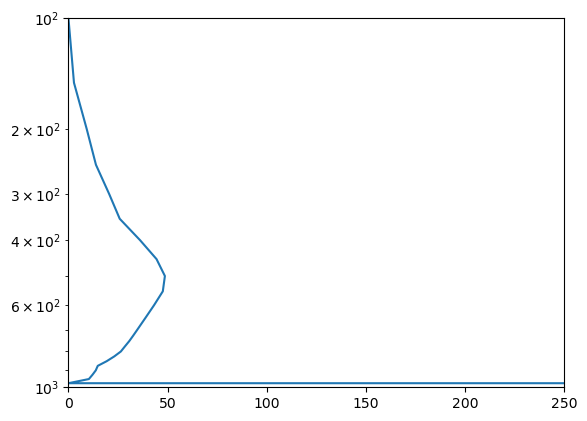

In [5]:

plt.plot(CMFMC_meanprof, M2prs)
plt.ylim(1000,100)
plt.yscale('log')
plt.xlim(0,250)

with open('/glade/u/home/wsmith/ASM_Plotter/Analysis_Files/M2_CMFMC.pkl', 'wb') as f:
    pkl.dump((CMFMC_meanprof, M2prs),f)
